# Haberman's Survival Dataset — Basic Exploratory Data Analysis (EDA)

**Dataset size:** 306 records  
**Tools:** Python, NumPy, Pandas, Matplotlib  
**Platform:** Google Colab

## Project objective
Explore the age at operation, year of operation, number of positive axillary nodes, and recorded survival-status category.

This is a basic EDA exercise only. **No machine learning or medical predictions are performed.**

### Column descriptions
- `age`: Age of the patient at the time of operation.
- `operation_year`: Year of operation, recorded as years after 1900 in the original dataset.
- `positive_nodes`: Number of positive axillary nodes detected.
- `survival_status`: `1` = survived 5 years or longer; `2` = died within 5 years after operation.

*These labels describe the dataset's recorded categories; they should not be used to make predictions about an individual.*

## 1. Install and import the required libraries
Run this cell first in Google Colab.

In [1]:
!pip -q install ucimlrepo

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the dataset
The dataset is fetched from the UCI Machine Learning Repository (dataset ID: 43).

In [2]:
# Fetch Haberman's Survival dataset from UCI
haberman = fetch_ucirepo(id=43)

# Combine the feature columns and target column
X = haberman.data.features
y = haberman.data.targets
df = pd.concat([X, y], axis=1)

# Give the columns clear names for this analysis
df.columns = [
    "age",
    "operation_year",
    "positive_nodes",
    "survival_status"
]

print("Dataset loaded successfully.")
print("Number of rows and columns:", df.shape)

Dataset loaded successfully.
Number of rows and columns: (306, 4)


## 3. Inspect the dataset
Display the first rows, last rows, shape, data types, and descriptive statistics.

In [3]:
print("First 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())

print("\nDataset shape:")
print(df.shape)

print("\nDataset information:")
df.info()

print("\nDescriptive statistics:")
display(df.describe())

First 5 rows:


,age,operation_year,positive_nodes,survival_status
0,30,64,1,1
1,30,62,3,1
2,30,65,0,1
3,31,59,2,1
4,31,65,4,1



Last 5 rows:


,age,operation_year,positive_nodes,survival_status
301,75,62,1,1
302,76,67,0,1
303,77,65,3,1
304,78,65,1,2
305,83,58,2,2



Dataset shape:
(306, 4)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 306 entries, 0 to 305
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   age              306 non-null    int64
 1   operation_year   306 non-null    int64
 2   positive_nodes   306 non-null    int64
 3   survival_status  306 non-null    int64
dtypes: int64(4)
memory usage: 9.7 KB

Descriptive statistics:


,age,operation_year,positive_nodes,survival_status
count,306.000000,306.000000,306.000000,306.000000
mean,52.457516,62.852941,4.026144,1.264706
std,10.803452,3.249405,7.189654,0.441899
min,30.000000,58.000000,0.000000,1.000000
25%,44.000000,60.000000,0.000000,1.000000
50%,52.000000,63.000000,1.000000,1.000000
75%,60.750000,65.750000,4.000000,2.000000
max,83.000000,69.000000,52.000000,2.000000


## 4. Check missing values and duplicate records

In [4]:
print("Missing values in each column:")
display(df.isnull().sum())

print("Total missing values:", df.isnull().sum().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

Missing values in each column:


,0
age,0
operation_year,0
positive_nodes,0
survival_status,0


Total missing values: 0

Number of duplicate rows:
17


## 5. Question 1 — Count records in each survival-status category

In [5]:
status_counts = df["survival_status"].value_counts().sort_index()

print("Records in each survival-status category:")
display(status_counts.rename_axis("survival_status").to_frame("record_count"))

print("\nStatus labels:")
print("1 = Survived 5 years or longer")
print("2 = Died within 5 years after operation")

Records in each survival-status category:


,record_count
survival_status,
1,225
2,81



Status labels:
1 = Survived 5 years or longer
2 = Died within 5 years after operation


## 6. Question 2 — Calculate age statistics using NumPy

In [6]:
# Convert the Pandas age column into a NumPy array
age_array = df["age"].to_numpy()

age_mean = np.mean(age_array)
age_median = np.median(age_array)
age_min = np.min(age_array)
age_max = np.max(age_array)

print("Age statistics:")
print("Average age:", round(age_mean, 2))
print("Median age:", age_median)
print("Minimum age:", age_min)
print("Maximum age:", age_max)

Age statistics:
Average age: 52.46
Median age: 52.0
Minimum age: 30
Maximum age: 83


## 7. Question 3 — Find the average number of positive axillary nodes

In [7]:
nodes_array = df["positive_nodes"].to_numpy()
average_nodes = np.mean(nodes_array)

print("Average number of positive axillary nodes:", round(average_nodes, 2))

Average number of positive axillary nodes: 4.03


## 8. Question 4 — Compare average age and node counts across the two status groups

In [8]:
group_comparison = (
    df.groupby("survival_status")[["age", "positive_nodes"]]
      .mean()
      .round(2)
)

print("Average age and positive nodes by survival-status category:")
display(group_comparison)

Average age and positive nodes by survival-status category:


,age,positive_nodes
survival_status,,
1,52.02,2.79
2,53.68,7.46


## 9. Question 5 — Find the operation years with the most records

The original year values are stored as years after 1900. The next cell adds 1900 to display calendar years.

In [9]:
# Count records for each original operation-year value
year_counts = df["operation_year"].value_counts().sort_index()

# Convert years-after-1900 to calendar years for display
calendar_year_counts = year_counts.copy()
calendar_year_counts.index = calendar_year_counts.index + 1900
calendar_year_counts.index.name = "operation_year"

print("Records by operation year:")
display(calendar_year_counts.to_frame("record_count"))

print("\nOperation years with the most records:")
display(
    calendar_year_counts.sort_values(ascending=False)
                        .head(5)
                        .to_frame("record_count")
)

Records by operation year:


,record_count
operation_year,
1958,36
1959,27
1960,28
1961,26
1962,23
1963,30
1964,31
1965,28
1966,28



Operation years with the most records:


,record_count
operation_year,
1958,36
1964,31
1963,30
1960,28
1965,28


## 10. Pandas filtering and sorting

Examples of filtering records and sorting the dataset by age.

In [10]:
print("First 5 records where age is greater than 50:")
display(df[df["age"] > 50].head())

print("\n5 records with the highest ages:")
display(df.sort_values(by="age", ascending=False).head())

First 5 records where age is greater than 50:


,age,operation_year,positive_nodes,survival_status
136,51,59,13,2
137,51,59,3,2
138,51,64,7,1
139,51,59,1,1
140,51,65,0,1



5 records with the highest ages:


,age,operation_year,positive_nodes,survival_status
305,83,58,2,2
304,78,65,1,2
303,77,65,3,1
302,76,67,0,1
301,75,62,1,1


## 11. Chart 1 — Survival-status distribution

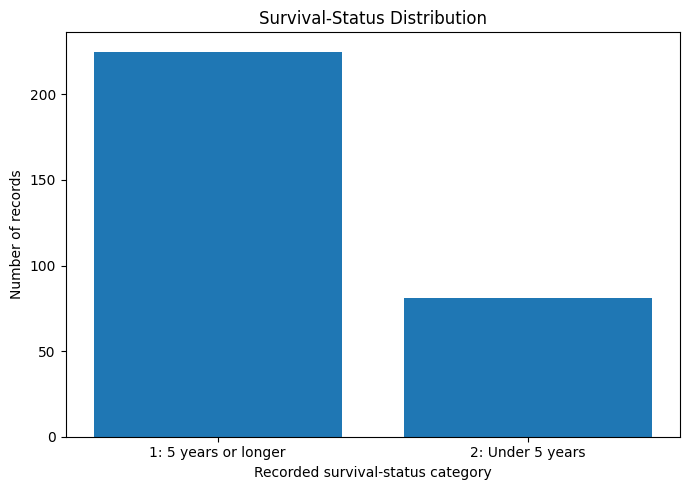

In [11]:
status_counts = df["survival_status"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.bar(status_counts.index.astype(str), status_counts.values)
plt.title("Survival-Status Distribution")
plt.xlabel("Recorded survival-status category")
plt.ylabel("Number of records")
plt.xticks(["1", "2"], ["1: 5 years or longer", "2: Under 5 years"])
plt.tight_layout()
plt.show()

## 12. Chart 2 — Age distribution

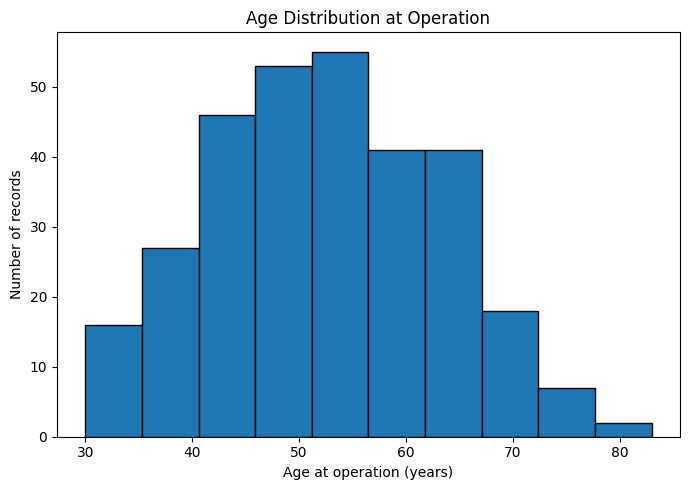

In [12]:
plt.figure(figsize=(7, 5))
plt.hist(df["age"], bins=10, edgecolor="black")
plt.title("Age Distribution at Operation")
plt.xlabel("Age at operation (years)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

## 13. Three observations

Run the next cell to generate three observations from the dataset. Review the values and write them in your own words in the space below.

In [13]:
most_common_status = status_counts.idxmax()
most_common_count = status_counts.max()
most_common_year = calendar_year_counts.idxmax()
most_common_year_count = calendar_year_counts.max()

print("OBSERVATION 1:")
print(
    f"Survival-status category {most_common_status} has the highest number "
    f"of records ({most_common_count})."
)

print("\nOBSERVATION 2:")
print(
    f"The average age at operation is {age_mean:.2f} years "
    f"(median: {age_median:.1f} years)."
)

print("\nOBSERVATION 3:")
print(
    f"The average number of positive axillary nodes is {average_nodes:.2f}. "
    f"The operation year with the most records is {most_common_year} "
    f"({most_common_year_count} records)."
)

print("\nEDA completed successfully.")

OBSERVATION 1:
Survival-status category 1 has the highest number of records (225).

OBSERVATION 2:
The average age at operation is 52.46 years (median: 52.0 years).

OBSERVATION 3:
The average number of positive axillary nodes is 4.03. The operation year with the most records is 1958 (36 records).

EDA completed successfully.


## 14. Conclusion

This project used Python, NumPy, Pandas, and Matplotlib to perform basic exploratory data analysis on the 306-row Haberman's Survival dataset. It examined survival-status counts, age statistics, positive axillary-node counts, operation-year frequencies, missing values, duplicate rows, and two simple charts.

**No machine learning model was used, and no medical predictions were made.**

**Dataset source:** [UCI Machine Learning Repository — Haberman's Survival](https://archive.ics.uci.edu/dataset/43/haberman+s+survival)